**Write the names of all group members (max. 5 members)**:
- Karim, Addi

When submitting your work, please follow closely the template below.

Implement the models from scratch using PyTorch (you may adapt `demo.ipynb`) or TensorFlow. Do not use third-party repositories containing ready-made deep hedging implementations. One submission per team is enough.

Make sure all requested results are visible in the executed notebook. A concise **Project Report** is required at the end of the notebook.

# Exercise 1

### 1.a) Use Itô’s formula to check that $S_t=s_0\exp(\sigma W_t-\frac12\sigma^2t)$ solves the Black–Scholes SDE with $r=0$. 

In the following I use $f(t,W_t) = S_t$ interchangeably. To apply Itô's Lemma, we first compute the following partial derivatives:
$$\begin{align*}
    \partial_t f &= -\frac12 \sigma^2 s_0 \exp\left(\sigma W_t-\frac12\sigma^2t\right) = -\frac12 S_t \\
    \partial_w f &= \sigma S_t\\
    \partial_w^2 f &= \sigma^2 S_t
\end{align*}$$
With this, we can now compute the total derivative of $f$ using Itô's Lemma:
$$\begin{align*}
    \text{d}f(t,W_t) &= \left(\partial_t f + \frac12 \partial_w^2 f\right)\text{d}t + \partial_w f \text{d}W_t \\
        &= \left(-\frac12 \sigma^2 S_t + \frac12 \sigma^2 S_t\right)\text{d}t + \sigma S_t \text{d}W_t \\
        &= \sigma S_t \text{d}W_t
\end{align*}$$
We can clearly see therefore that $S_t=s_0\exp(\sigma W_t-\frac12\sigma^2t)$ is a solution to the Black-Scholes SDE with $r=0$.

### Question 1.b - Generate dataset

In [42]:
import numpy as np
import pandas as pd
# Generate 100,000 training paths and 10,000 independent test paths.
# Parameters: N=30, s0=1, T=1/4 year, sigma=0.35, r=0.
# Use the exact geometric Brownian motion update specified in Problem 1(b).
# Each path contains N+1=31 prices, including S0 and ST.

N = 30
s_0 = 1
T= 0.25
sigma = 0.35
train_size = 100000
test_size = 10000

def generate_data(ds_size, N=30, s_0=1, T=0.25, sigma=0.35, r=0):
    dataset = np.zeros((ds_size, N+1))
    std = sigma * np.sqrt(T/N)
    for i in range(ds_size):
        z_i = np.random.randn(N)
        dataset[i, 0] = s_0
        for j in range(N):
            dataset[i,j+1] = dataset[i,j] * np.exp(-0.5*std**2 + std*z_i[j])

    return dataset

# Generate the training set
ds_train = generate_data(train_size)

# Generate the test set
ds_train = generate_data(test_size)

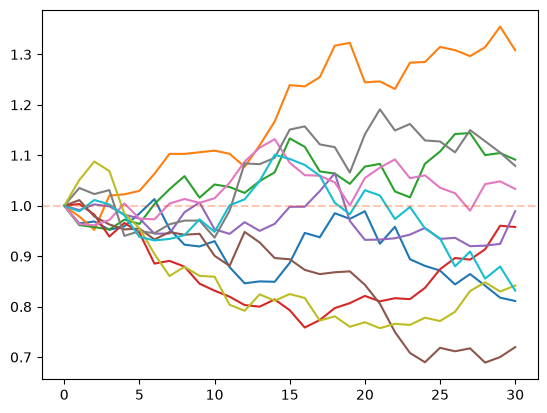

In [44]:
import matplotlib.pyplot as plt
x = range(N+1)
plt.plot(x, ds_train[:10,:].T)
plt.axhline(1, linestyle="--",color="orangered",alpha=0.3)
plt.show()

### Question 1.c - Model implementation

In [ ]:
# Implement the deep hedging model from scratch.
# You may use and edit the code shown in demo.ipynb.
# Create 30 separate networks H_0,...,H_29, each with its own parameters.
# Each network takes the current stock price as input and returns the shares to hold.
# Do not use future prices as inputs to the trading decision.

### Question 1.d - Model training

In [ ]:
# Implement the call payoff with strike K=1 and maturity T=1/4 year.

# Implement the Black-Scholes call-price formula (3).
# Compute and fix the initial premium p=C(0,s0); p is not trained.

# Train all 30 networks jointly by minimizing equation (2) on the training set.

### Question 1.e - Model evaluation

In [ ]:
# Evaluate the trained hedge on the 10,000 independent test paths.
# Compute P&L = p + sum_j H_j(S_tj)*(S_tj+1-S_tj) - g(ST).
# Plot its histogram and print the empirical mean and standard deviation.

### Question 1.f(i) - Compute analytical solution

Show a **step-by-step** derivation of the analytical hedging strategy:

\begin{align*}
H^{\text{BS}}_t(s) & = \frac{\partial C(t, s)}{\partial s} \\
& = \ldots
\end{align*}

No points for solutions without explicit derivation.

### Question 1.f(ii) - P&L comparison with the analytical hedge

In [ ]:
# Implement the formula you found
# Rebalance at t_0,...,t_29 using the same test paths, premium and payoff as in 1.e.
# Compute P&L using the same sign convention as in 1.e.
# Plot histograms of both P&L distributions and print their means and standard deviations.

How does your deep hedging model compare with the analytical solution? If it's worse, you must improve its performance. A few questions for you to consider...

Have you trained your deep hedging model well?
- Are the losses centered on zero? ($10^{-5} \approx 0$)
- Is their standard deviation comparable with that of the analytical solution?

How can you improve performance?
- train for more epochs
- try a different learning rate
- change the networks' architectures (first try more hidden neurons, then try more hidden layers)
- try different batch sizes
- use a learning rate scheduler (see https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate)
- try a different activation function (e.g. $\tanh$)
- implement regularization (use the `weight_decay` argument in the optimizer)
- implement batch-normalization (see https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html)
- experiment with different optimizers
- ask in the forum

### Question 1.g - Learned strategy comparison with analytical solution

In [ ]:
# Compare the hedge functions at j=0,10,20,29.
# Make a grid of stock prices s in [0.5,1.5].
# Create four plots or panels, one per selected date.
# In each panel, overlay H_j(s) and the analytical delta evaluated on the same price grid.
# Label the date, both strategies, and axes (stock price and number of shares).

- For what times $t_j$ are the two functions most similar? 
- Why?

# Exercise 2

### Question 2.a - Generate dataset

In [ ]:
# Generate 100,000 training paths and 10,000 independent test paths of (S,V).
# Parameters: N=30, s0=1, T=1/4 year, rho=-0.3, a=4, b=0.5, v0=0.5, sigma=1.
# Each stock and variance path contains N+1=31 values.

# (i) Write a function to simulate V using the exact noncentral chi-square transitions.

# (ii) Write a function to simulate S using the supplied simplified Broadie-Kaya update.

### Question 2.b - Model implementation

In [ ]:
# Implement the deep hedging model for a generic AVaR level alpha.
# Create 30 separate networks, each taking (current stock price, current variance)
# as input and returning one stock holding.
# Implement the AVaR objective in equation (6), with a trainable scalar threshold w.

### Question 2.c - Model training

In [ ]:
# Train two separate deep hedging models for alpha=0.5 and alpha=0.9.
# Use the call option with strike K=1 and maturity T=1/4 year.
# Minimize equation (6), jointly optimizing all network parameters and scalar w.
# Each model has its own networks and one threshold w shared across its paths.
# Include w in the optimizer; do not fix a Black-Scholes premium in this objective.

### Question 2.d - Price comparison

In [ ]:
# Freeze each trained model and its threshold w.
# Evaluate equation (6) on the same 10,000 test paths to estimate each price p.
# Print p for alpha=0.5 and alpha=0.9.
# Explain which price is higher and why.

### Question 2.e - P&L comparison

In [ ]:
# Compute test P&L for alpha=0.5 and alpha=0.9.
# Use the same test paths for both models.
# Plot both P&L histograms with comparable axes and binning.
# Print the empirical mean and standard deviation for each distribution.

## Project Report

Provide a concise synthesis of your findings across both problems. Refer to the results above and focus on the main conclusions.

### Approach

Briefly describe how you simulated the paths, trained the hedges, and evaluated them on the test sets.

### Key results

Summarize the comparison between the learned hedge and Black–Scholes delta. For Heston, report the two estimated premiums and the main differences in test P&L.

### Interpretation

Explain how closely the learned holdings matched delta at the selected dates and how the AVaR level affected the premium and the P&L distribution.

### Robustness

Discuss how simulation noise and random network initialization could affect your conclusions. No additional experiments are required.

### Limitations

Discuss the main limitations, such as discrete rebalancing and reliance on simulated markets.